# 7. Zero-Finding

*Physical Modeling in MATLAB* by Allen B. Downey. Run each code cell in order with Shift+Enter; you can change the code and run it again.

In this chapter we’ll use the MATLAB function `fzero` to solve nonlinear equations. Nonlinear equations are useful for modeling physical systems; for example, in one of the exercises at the end of this chapter, you can use `fzero` to find the equilibrium point of an object floating on water. Using `fzero` is also an opportunity to learn about *function handles*, which we’ll need for the following chapters.

## Solving Nonlinear Equations

What does it mean to “solve” an equation? That may seem like an obvious question, but let’s take a minute to think about it, starting with a simple example.

Suppose we want to know the value of a variable, $x$, but all we know about it is the relationship $x^2 = a$. If you’ve taken algebra, you probably know how to solve this equation: you take the square root of both sides and get $x = \pm \sqrt{a}$. Then, with the satisfaction of a job well done, you move on to the next problem.

But what have you really done? The relationship you derived is equivalent to the relationship you started with—they contain the same information about $x$—so why is the second one preferable to the first?

There are two reasons. One is that the relationship is now *explicit* in $x$: because $x$ is all alone on the left side, we can treat the right side as a recipe for computing $x$, assuming that we know the value of $a$.

The other reason is that the recipe is written in terms of operations we know how to perform. Assuming that we know how to compute square roots, we can compute the value of $x$ for any value of $a$.

When people talk about solving an equation, what they usually mean is something like “finding an equivalent relationship that is explicit in one of the variables.” In the context of this book, that’s what we’ll call an *analytic solution*, to distinguish it from a *numerical solution*, which is what we are going to do next.

To demonstrate a numerical solution, consider the equation $x^2 - 2x = 3$. You could solve this analytically, either by factoring it or by using the quadratic formula, and you would discover that there are two solutions, $x=3$ and $x=-1$. Alternatively, you could solve it numerically by rewriting it as $x = \pm \sqrt{2x+3}$.

This equation is not explicit, since $x$ appears on both sides, so it’s not clear that this move did any good at all. But suppose we had reason to expect a solution near 4. We could start with $x=4$ as an *initial value* and then use the equation $x = \sqrt{2x+3}$ to compute successive approximations of the solution. (To understand why this works, see <https://greenteapress.com/matlab/fixed>.)

Here’s what happens:

In [2]:
x = 4;
x = sqrt(2*x+3)
x = sqrt(2*x+3)
x = sqrt(2*x+3)
x = sqrt(2*x+3)
x = sqrt(2*x+3)

x = 3.3166


x = 3.1037


x = 3.0344


x = 3.0114


x = 3.0038


After each iteration, `x` is closer to the correct answer, and after five iterations the relative error is about 0.1 percent, which is good enough for most purposes.

Techniques that generate numerical solutions are called *numerical methods*. The nice thing about the method we just used is that it’s simple. But it doesn’t always work, and it’s not often used in practice. We’ll see a better alternative in the next section.

### Zero-Finding

The MATLAB function `fzero` that uses numerical methods to search for solutions to nonlinear equations. In order to use it, we have to rewrite the equation as an *error function*, like this:

$$f(x) = x^2 - 2x -3$$

The value of the error function is 0 if $x$ is a solution and nonzero if it is not. This function is useful because we can use values of $f(x)$, evaluated at various values of $x$, to infer the location of the solutions. And that’s what `fzero` does. Values of $x$ where $f(x) = 0$ are called zeros of the function or *roots*.

To use `fzero` you have to define a MATLAB function that computes the error function, like this:

In [3]:
function res = error_func(x)
    res = x^2 - 2*x -3;
end

You can call `error_func` from the Command Window and confirm that $3$ and $-1$ are zeros:

In [4]:
error_func(3)
error_func(-1)

ans = 0


ans = 0


But let’s pretend that we don’t know where the roots are; we only know that one of them is near 4. Then we could call `fzero` like this:

In [5]:
fzero(@error_func, 4)

ans = 3


Success! We found one of the zeros.

The first argument is a *function handle* that specifies the error function. The `@` symbol allows us to name the function without calling it. The interesting thing here is that you’re not actually calling `error_func` directly; you’re just telling `fzero` where it is. In turn, `fzero` calls your error function—more than once, in fact.

The second argument is the initial value. If we provide a different value, we get a different root (at least sometimes).

In [6]:
fzero(@error_func, -2)

ans = -1


Alternatively, if you know two values that bracket the root, you can provide both.

In [7]:
fzero(@error_func, [2,4])

ans = 3.0000


The second argument is a vector that contains two elements.

You might be curious to know how many times `fzero` calls your function, and where. If you modify `error_func` so that it displays the value of `x` when it is called and then run `fzero` again, you get

In [8]:
% error_func modified to display x each time fzero calls it
function res = error_func(x)
    x
    res = x^2 - 2*x -3;
end

In [9]:
fzero(@error_func, [2,4])

x = 2
x = 4
x = 2.7500
x = 3.3750
x = 3.0079
x = 3.0000
x = 3.0000
x = 3.0000
x = 3.0000
x = 3.0000
ans = 3.0000


Not surprisingly, it starts by computing $f(2)$ and $f(4)$. Then it computes a point in the interval, $2.75$, and evaluates $f$ there. After each iteration, the interval gets smaller and the guess gets closer to the true root. The `fzero` function stops when the interval is so small that the estimated zero is correct to about 15 digits.

If you’d like to know more about how `fzero` works, see Section 15.2.

### What Could Go Wrong?

The most common problem people have with `fzero` is leaving out the `@`. In that case, you get something like so:

```
fzero(error_func, [2,4])
```

In MATLAB, the error message is:

```
Not enough input arguments.

Error in error_func (line 2)
    res = x^2 - 2*x -3;
```

In Octave, it is:

```
error: 'x' undefined
```

The error occurs because MATLAB treats the first argument as a function call, so it calls `error_func` with no arguments.

Another common problem is writing an error function that never assigns a value to the output variable. In general, functions should *always* assign a value to the output variable, but MATLAB doesn’t enforce this rule, so it’s easy to forget.

For example, if you write

In [10]:
function res = error_func(x)
    y = x^2 - 2*x -3
end

and then call it from the Command Window,

In [11]:
error_func(4)

y = 5


it looks like it worked, but don’t be fooled. This function assigns a value to `y`, and it displays the result, but when the function ends, `y` disappears along with the function’s workspace. If you try to use it with `fzero`, you get

```
>> fzero(@error_func, [2,4])
y = -3

Error using fzero (line 231)
FZERO cannot continue because user-supplied function_handle ==>
error_func failed with the error below.

Output argument "res" (and maybe others) not assigned during call
to "error_func".
```

In Octave, it is:

```
error: value on right hand side of assignment is undefined
```

If you read it carefully, this is a pretty good error message, provided you understand that “output argument” and “output variable” are the same thing.

You would have seen the same error message when calling `error_func` from the interpreter, if you had assigned the result to a variable:

```
x = error_func(4)
```

In Octave, it is:

```
error: value on right hand side of assignment is undefined
```

Another thing can go wrong: if you provide an interval for the initial guess and it doesn’t actually contain a root, you get

In [12]:
% Back to the version of error_func that works
function res = error_func(x)
    res = x^2 - 2*x -3;
end

```
fzero(@error_func, [0,1])
```

In MATLAB, the error message is:

```
Error using fzero (line 272)
The function values at the interval endpoints must differ in sign.
```

In Octave, it is:

```
error: fzero: not a valid initial bracketing
```

There is one other thing that can go wrong when you use `fzero`, but this one is less likely to be your fault. It’s possible that `fzero` won’t be able to find a root.

Generally, `fzero` is robust, so you may never have a problem, but you should remember that there is no guarantee that `fzero` will work, especially if you provide a single value as an initial guess. Even if you provide an interval that brackets a root, things can still go wrong if the error function is discontinuous.

### Choosing an Initial Value

The better your initial value is, the more likely it is that `fzero` will work, and the fewer iterations it will need.

When you’re solving problems in the real world, you’ll usually have some intuition about the answer. This intuition is often enough to provide a good initial guess.

If not, another way to choose an initial guess is to plot the error function and approximate the zeros visually. If you have a function like `error_func` that takes a scalar input variable and returns a scalar output variable, you can plot it with `ezplot`:

```
>> ezplot(@error_func, [-2,5])
```

In Octave, it is:

```
error: for x^y, only square matrix arguments are permitted and one argument must be scalar.  Use .^ for elementwise power.
```

The first argument is a function handle; the second is the interval you want to plot the function in. By examining the plot, you can estimate the locations of the two roots.

### Vectorizing Functions

When you call `ezplot`, you might get the following warning (or error, if you’re using Octave):

```
Warning: Function failed to evaluate on array inputs;
vectorizing the function may speed up its evaluation and
avoid the need to loop over array elements.
```

This means that MATLAB tried to call `error_func` with a vector, and it failed. The problem is that it uses the `*` and `^` operators. With vectors, those operators don’t do what we want, which is *element-wise* multiplication and exponentiation (see “Vector Arithmetic” in Section 4.2).

If you rewrite `error_func` like this:

In [13]:
function res = error_func(x)
    res = x.^2 - 2.*x -3;
end

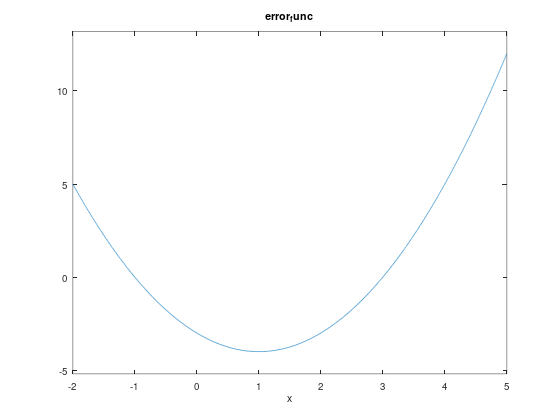

In [14]:
ezplot(@error_func, [-2,5])

the warning message goes away, and `ezplot` runs faster.

## Debugging

When you start writing longer programs, you might spend more time debugging. So we’ll end this chapter with some debugging tips.

### More Name Collisions

Functions and variables occupy the same workspace, which means that whenever a name appears in an expression, MATLAB starts by looking for a variable with that name; if there isn’t one, it looks for a function.

As a result, if you have a variable with the same name as a function, the variable *shadows* the function; metaphorically, you can’t see the function because the variable is in the way.

For example, if you assign a value to `sin` and then try to use the `sin` function, you might get an error:

```
sin = 3;
sin(5)
```

In Octave, it is:

```
error: sin(5): out of bound 1 (dimensions are 1x1)
```

Since the value we assigned to `sin` is a number, and a number is considered a $1 \times 1$ matrix, MATLAB tries to access the fifth element of the matrix and finds that there isn’t one.

In this case, MATLAB is able to detect the error, and the error message is pretty helpful. But if the value of `sin` were a vector, or if the argument were smaller, you would be in trouble. For example,

In [15]:
sin = 3;
sin(1)

ans = 3


Just to review, the sine of 1 is not 3!

You can avoid these problems by choosing function names carefully. Use long, descriptive names for functions, not single letters like `f`. To be even clearer, use function names that end in `func`. And before you define a function, check whether MATLAB already has a function with the same name.

### Debugging Your Head

When you’re working with a new function or a new language feature for the first time, you should test it in isolation before you put it into your program.

For example, suppose you know that `x` is the sine of some angle and you want to find the angle. You find the MATLAB function `asin`, and you’re pretty sure it computes the inverse sine function. Pretty sure is not good enough; you want to be very sure.

Since we know $\sin 0 = 0$, we could try

In [16]:
asin(0)

ans = 0


which is correct. Now, we also know that the sine of $90$° is 1, so if we try `asin(1)`, we expect the answer to be 90, right?

In [17]:
asin(1)

ans = 1.5708


Oops. We forgot that the trig functions in MATLAB work in radians, not degrees. The answer we got is $\pi/2$, which is $90$°, in radians.

With this kind of testing, you’re not really checking for errors in your program; you’re checking your understanding. If you make an error because you are confused about how MATLAB works, it might take a long time to find, because when you look at the code, it looks right.

Which brings us to the Seventh Theorem of Debugging:

> The worst bugs aren’t in your code; they’re in your head.

## Chapter Review

This chapter introduced `fzero`, a function we can use to solve nonlinear equations. To use `fzero`, you have to write an error function and pass a function handle as an argument. Using functions in this way can be tricky at first, but get comfortable with it, because we are going to use it a lot.

Here are some terms from this chapter you might want to remember.

If we can solve an equation by performing algebraic operations and deriving an explicit way to compute a value, the result is an *analytic solution*. Otherwise, we can use a *numerical method*, which finds a *numerical solution* to the equation, which is usually an approximation.

To solve nonlinear equations, we often rewrite them as functions and then find one or more *zeros* of the function, that is, arguments that make the value of the function $0$.

A *function handle* is a way of referring to a function by name (and passing it as an argument) without calling it.

Finally, *shadowing* is a kind of name collision in which a new definition causes an existing definition to become invisible. In MATLAB, variable names can shadow built-in functions (with hilarious results).

In the next chapter, we’ll write functions that take vectors as inputs and return vectors as outputs.

## Exercises

Before you go on, you might want to work on the following exercises.

**Exercise 7.1.**

1.  Write a function called `cheby6` that evaluates the sixth Chebyshev polynomial. It should take an input variable, $x$, and return

    $$32 x^6 - 48 x^4 + 18 x^2 - 1$$

2.  Use `ezplot` to display a graph of this function in the interval from $-1$ to $1$. Estimate the location of any zeros in this range.

3.  Use `fzero` to find as many different roots as you can. Does `fzero` always find the root that is closest to the initial value?

**Exercise 7.2.** When a duck is floating on water, how much of its body is submerged? (This exercise is adapted from C. F. Gerald and P. O. Wheatley, *Applied Numerical Analysis*, 4th edition (Boston: Addison-Wesley, 1989).)

To estimate a solution to this problem, we’ll assume that the submerged part of a duck is well approximated by a section of a sphere. If a sphere with radius $r$ is submerged in water to a depth $d$, the volume of the sphere below the water line is

$$V = \frac{\pi}{3} (3r d^2 - d^3) \quad
\mbox{as long as} \quad d < 2 r$$

We’ll also assume that the density of a duck is $\rho = 0.3$ g/cm$^3$ (0.3 times the density of water) and that its mass is $\frac{4}{3} \pi r^3 \rho$ g.

Finally, according to the law of buoyancy, an object floats at the level where the weight of the displaced water equals the total weight of the object.

Here are some suggestions for how to proceed:

1.  Write an equation relating $\rho$, $d$, and $r$.

2.  Rearrange the equation so the right-hand side is zero. Our goal is to find values of $d$ that are roots of this equation.

3.  Write a MATLAB function that evaluates this function. Test it, then make it a quiet function.

4.  Make a guess about the value of $d_0$ to use as an initial value.

5.  Use `fzero` to find a root near $d_0$.

6.  Check to make sure the result makes sense. In particular, check that $d < 2 r$, because otherwise the volume equation doesn’t work!

7.  Try different values of $\rho$ and $r$ and see if you get the effect you expect. What happens as $\rho$ increases? Goes to infinity? Goes to zero? What happens as $r$ increases? Goes to infinity? Goes to zero?

In [18]:
% Solution

% Evaluate the 6th order Chebyshev polynomial.

function res = cheby6(x)
    res = 32 .* x.^6 - 48 .* x.^4 + 18 .* x.^2 - 1;
end

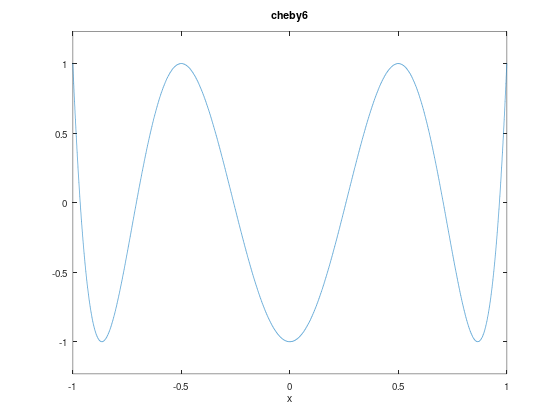

In [19]:
% Solution

ezplot(@cheby6, [-1, 1])

In [20]:
% Solution

function res = duck()
    err = error_func(2)
    ezplot(@error_func, [0, 20])
    res = fzero(@error_func, [0, 20]);   % the duck floats with 0 < d < 2r
end

function res = error_func(d)
    rho = 0.3;      % density in g / cm^3
    r = 10;         % radius in cm
    mass_duck = 4/3 * pi * r.^3 * rho;
    mass_water = pi / 3  * (3*r*d.^2 - d.^3);
    res = mass_water - mass_duck;
end

err = -1139.4
ans = 7.2651


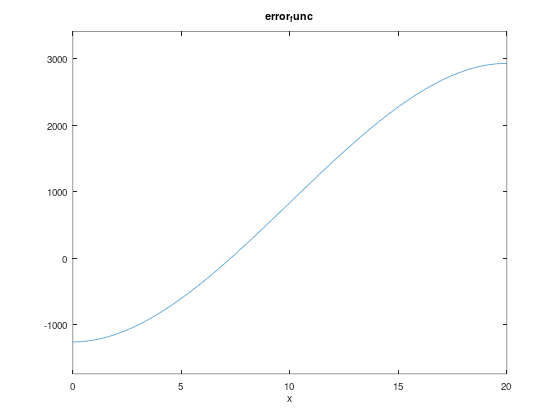

In [21]:
% Solution

duck